In [2]:
from PIL import Image
import numpy as np

color_arr = np.array(Image.open("cat.jpg"))
print(color_arr.shape)   # (360, 480, 3) — height, width, 3 colors
print(color_arr.dtype)   # uint8 — values 0 to 255

(2592, 3872, 3)
uint8


In [43]:
# https://docs.google.com/presentation/d/1AEoGvHBo3muvxcW_q3Oa8mBEtypB6mteofTzLaIMHVI/edit?usp=sharing

In [20]:
color_arr[0, 0]

array([214, 195, 181], dtype=uint8)

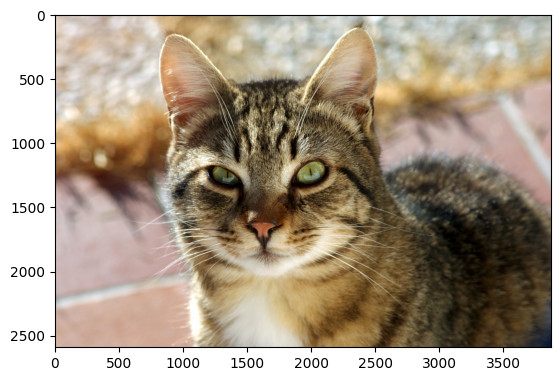

In [3]:
from matplotlib import pyplot as plt 

plt.imshow(color_arr)

In [5]:
color_arr.shape

(2592, 3872, 3)

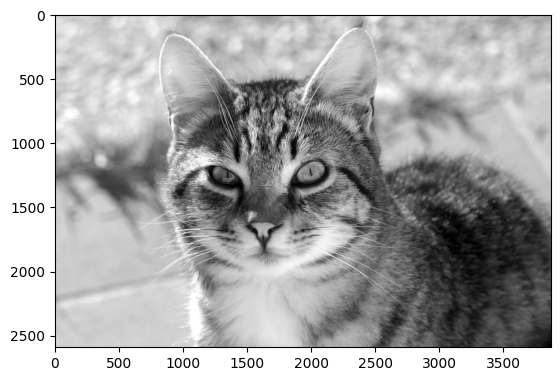

In [19]:
plt.imshow(color_arr[:,:,0], cmap='gray')

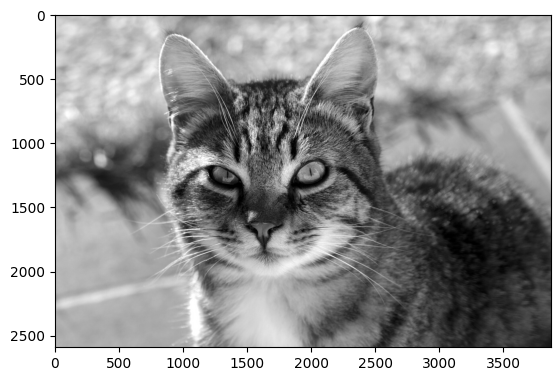

In [11]:
plt.imshow(color_arr[:,:,1], cmap='gray')

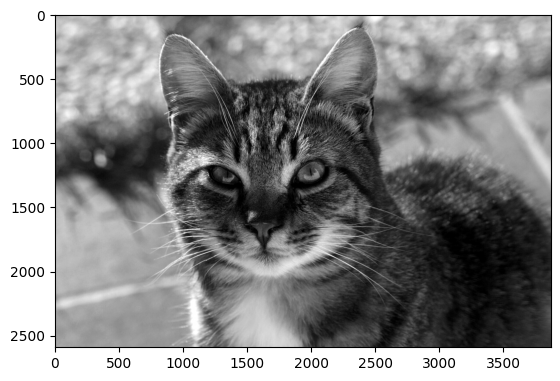

In [13]:
plt.imshow(color_arr[:,:,2], cmap='gray')

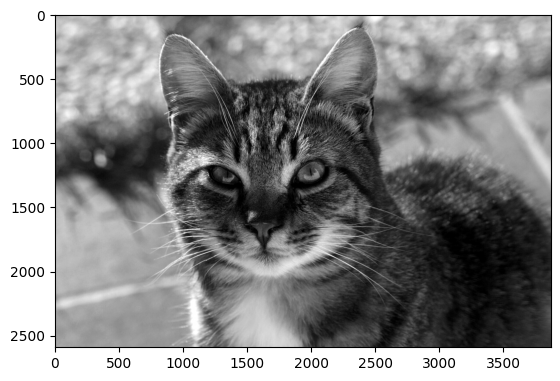

In [17]:
plt.imshow(color_arr[:,:,2], cmap='gray')

In [26]:
color_arr[0]

array([[214, 195, 181],
       [211, 192, 178],
       [209, 190, 176],
       ...,
       [174, 183, 180],
       [174, 183, 180],
       [174, 183, 180]], shape=(3872, 3), dtype=uint8)

In [27]:
gray_image[0]

array([196.66666667, 193.66666667, 191.66666667, ..., 179.        ,
       179.        , 179.        ], shape=(3872,))

In [15]:
gray_image = np.mean(color_arr, axis=2)

In [25]:
gray_image.shape,

((2592, 3872),)

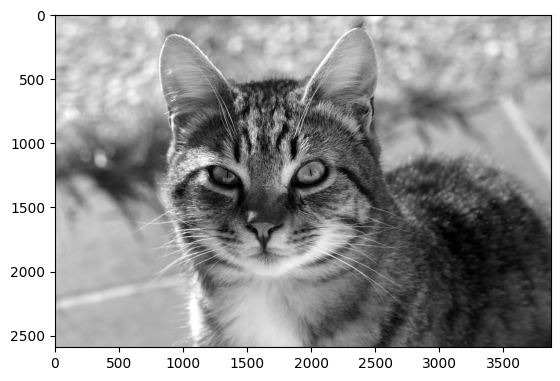

In [21]:
plt.imshow(gray_image, cmap='gray')

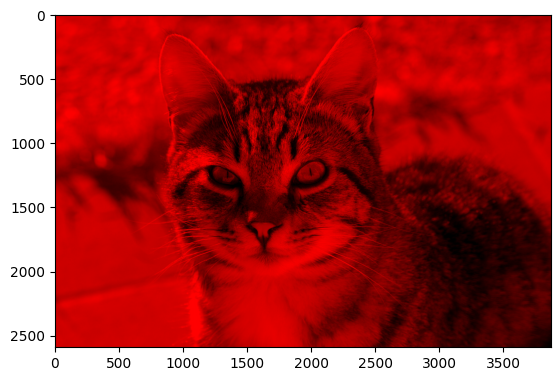

In [22]:
red_color_arr = color_arr.copy()
red_color_arr[:,:, 1] = 0
red_color_arr[:,:, 2] = 0

plt.imshow(red_color_arr)

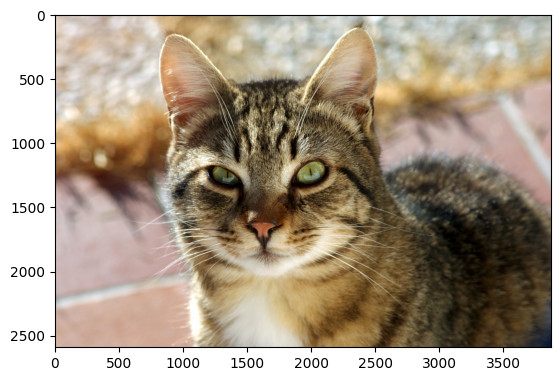

In [23]:
plt.imshow(color_arr)

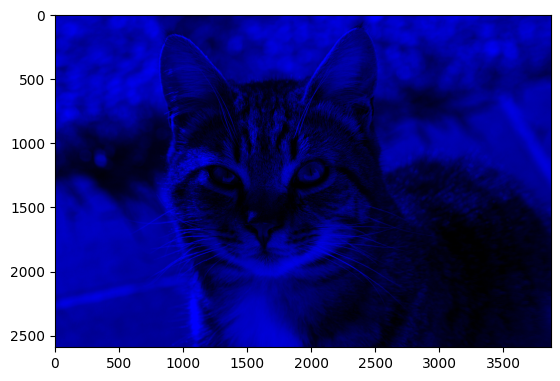

In [24]:
blucolor_arr = color_arr.copy()
blucolor_arr[:,:, 0] = 0
blucolor_arr[:,:, 1] = 0

plt.imshow(blucolor_arr)

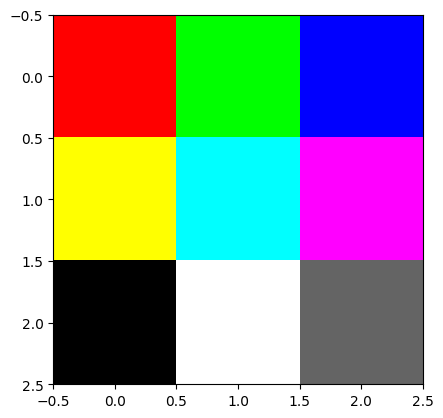

In [28]:
arr = np.array([
    [[255, 0, 0], [0, 255, 0], [0, 0, 255]],
    [[255, 255, 0], [0, 255, 255], [255, 0, 255]],
    [[0, 0, 0], [255, 255, 255], [100, 100, 100]],
])

plt.imshow(arr)

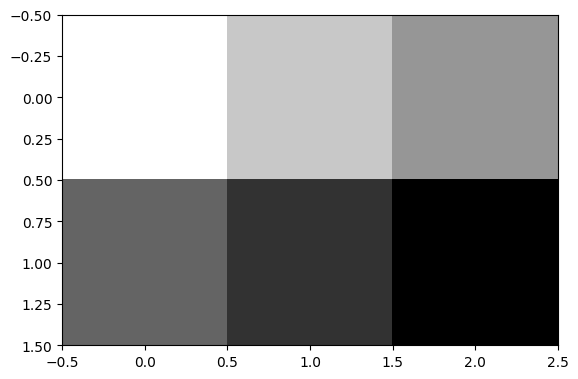

In [32]:
g_scale_img = np.array([
    [255, 200, 150],
    [100, 50, 0],
])
plt.imshow(g_scale_img, cmap='gray')

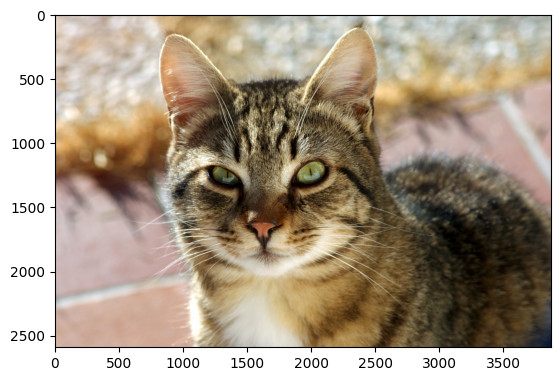

In [33]:
plt.imshow(color_arr)

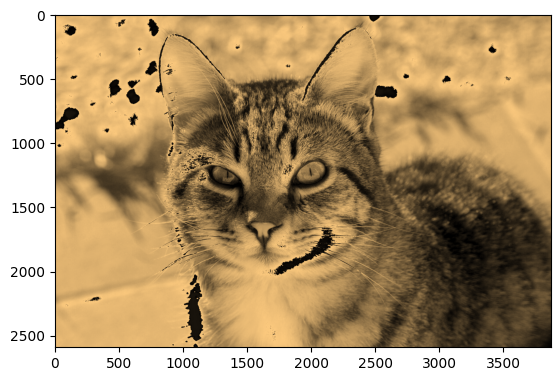

In [34]:
color_arr1 = color_arr.copy()
color_arr1[:, :, 0] = color_arr1[:, :, 0]*1.1
color_arr1[:, :, 1] = color_arr1[:, :, 0]*.8
color_arr1[:, :, 2] = color_arr1[:, :, 0]*.5

plt.imshow(color_arr1)

In [36]:
color_arr[0:2, :2, :]

array([[[214, 195, 181],
        [211, 192, 178]],

       [[213, 194, 180],
        [211, 192, 178]]], dtype=uint8)

In [ ]:
# Pick only the red color and reduce the size of this image by half

2x2x3 -> 
    [
    [[.25, 0, 0], [.25, 0, 0]],
     [.25, 0, 0], [.25, 0, 0]
    ]

In [ ]:
for i in range(len(color_arr)):
    for j in range(len(color_arr)):
        

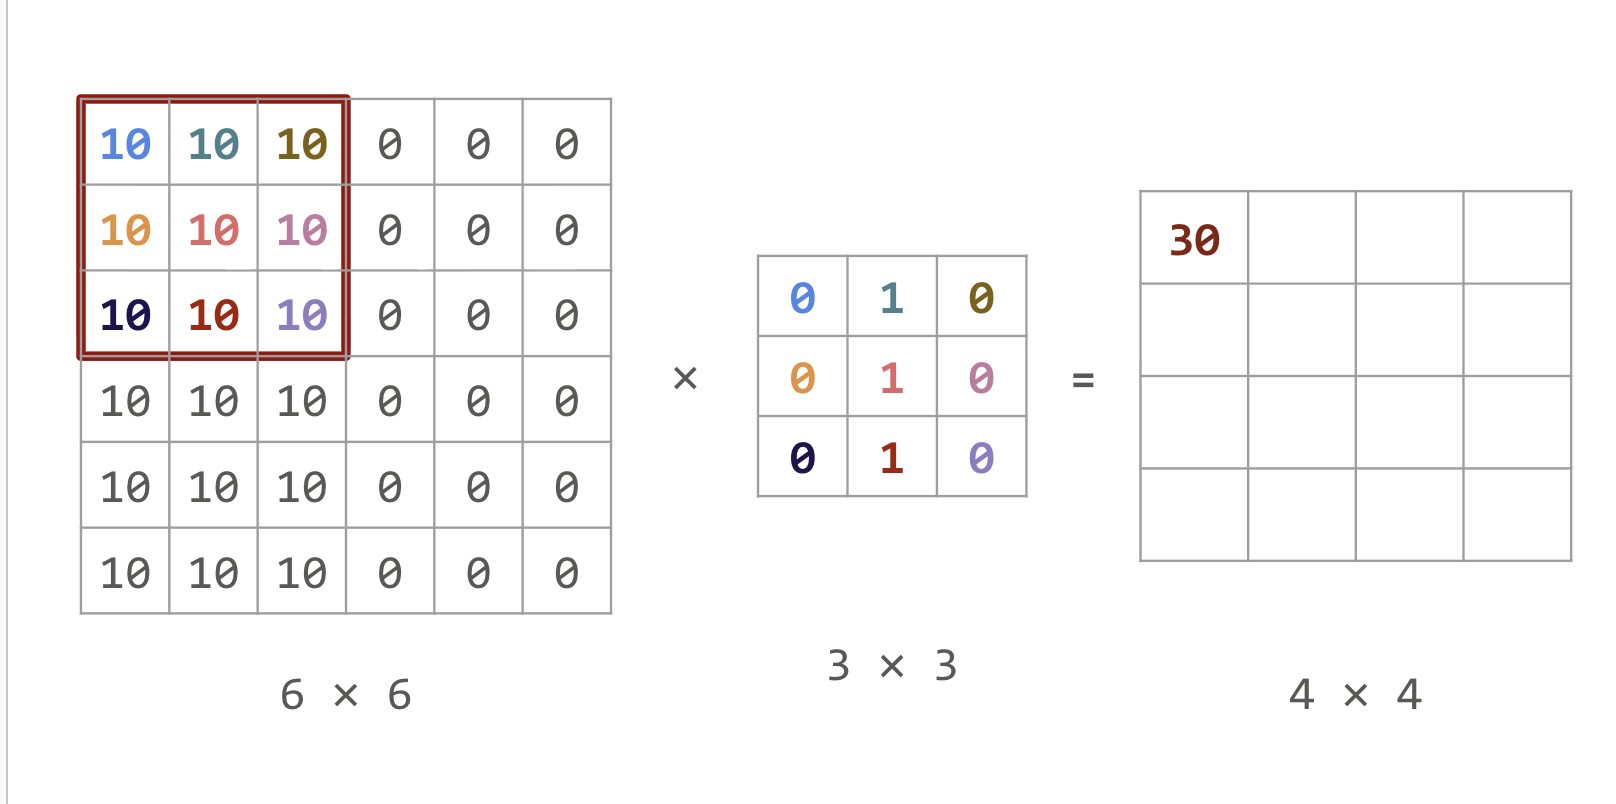

In [37]:
def convolve(grayscale, kernel_2d):
    ih, iw = grayscale.shape
    kh, kw = kernel_2d.shape
    ow = iw - (kw - 1)
    oh = ih - (kh - 1)
    output = np.zeros((ow, oh))
    for i in range(oh):
        for j in range(ow):
            output[i][j] = np.sum(grayscale[i:i+kh, j:j+kw, :]*kernel_2d)
    return output

Image shape: (256, 256, 1)


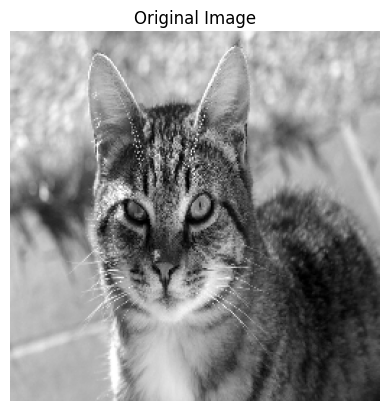

In [38]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = tf.keras.utils.load_img(
    "cat.jpg",
    target_size=(256, 256),
    color_mode="grayscale"
)

# Convert to numpy array
img_array = tf.keras.utils.img_to_array(img)

# Shape: (256, 256, 1)
print("Image shape:", img_array.shape)

plt.imshow(img_array[:, :, 0], cmap="gray")
plt.title("Original Image")
plt.axis("off")
plt.show()

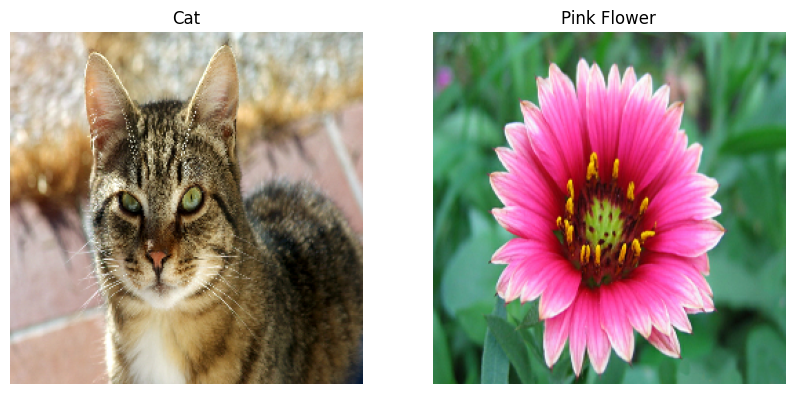

In [39]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Load and resize image
def load_image(path, size=(256, 256)):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, size)
    img = tf.cast(img, tf.float32) / 255.0
    return img

images = {
    "Cat": load_image("cat.jpg"),
    "Pink Flower": load_image("pink_flower.jpg")
}

# Display original images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img.numpy())
    ax.set_title(name)
    ax.axis("off")

plt.show()

In [40]:
filters = {
    "Identity": [
        [0, 0, 0],
        [0, 1, 0],
        [0, 0, 0]
    ],

    "Blur": [
        [1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9],
        [1/9, 1/9, 1/9]
    ],

    "Gaussian Blur": [
        [1/16, 2/16, 1/16],
        [2/16, 4/16, 2/16],
        [1/16, 2/16, 1/16]
    ],

    "Sharpen": [
        [0, -1, 0],
        [-1, 5, -1],
        [0, -1, 0]
    ],

    "Edge Detection": [
        [-1, -1, -1],
        [-1,  8, -1],
        [-1, -1, -1]
    ],

    "Emboss": [
        [-2, -1, 0],
        [-1,  1, 1],
        [0,  1, 2]
    ],

    "Sobel X": [
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ],

    "Sobel Y": [
        [-1, -2, -1],
        [0,   0,  0],
        [1,   2,  1]
    ]
}

In [41]:
def apply_filter(image, kernel):
    # Convert kernel to tensor
    kernel = tf.constant(kernel, dtype=tf.float32)

    # Shape: (3, 3, 1, 1)
    kernel = kernel[:, :, tf.newaxis, tf.newaxis]

    # Apply same kernel to all 3 RGB channels
    kernel = tf.tile(kernel, [1, 1, 3, 1])

    # Add batch dimension: (1, H, W, 3)
    image = image[tf.newaxis, ...]

    # Perform convolution
    output = tf.nn.depthwise_conv2d(
        image,
        kernel,
        strides=[1, 1, 1, 1],
        padding="SAME"
    )

    # Remove batch dimension
    return output[0]

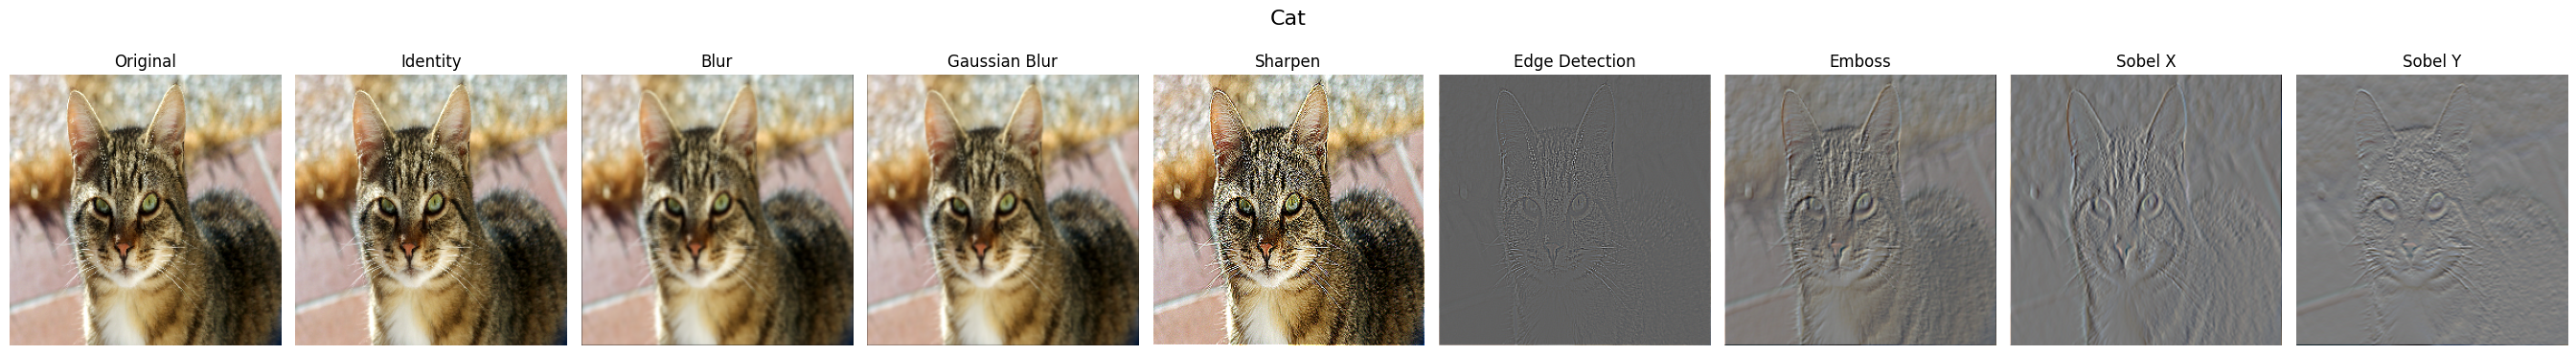

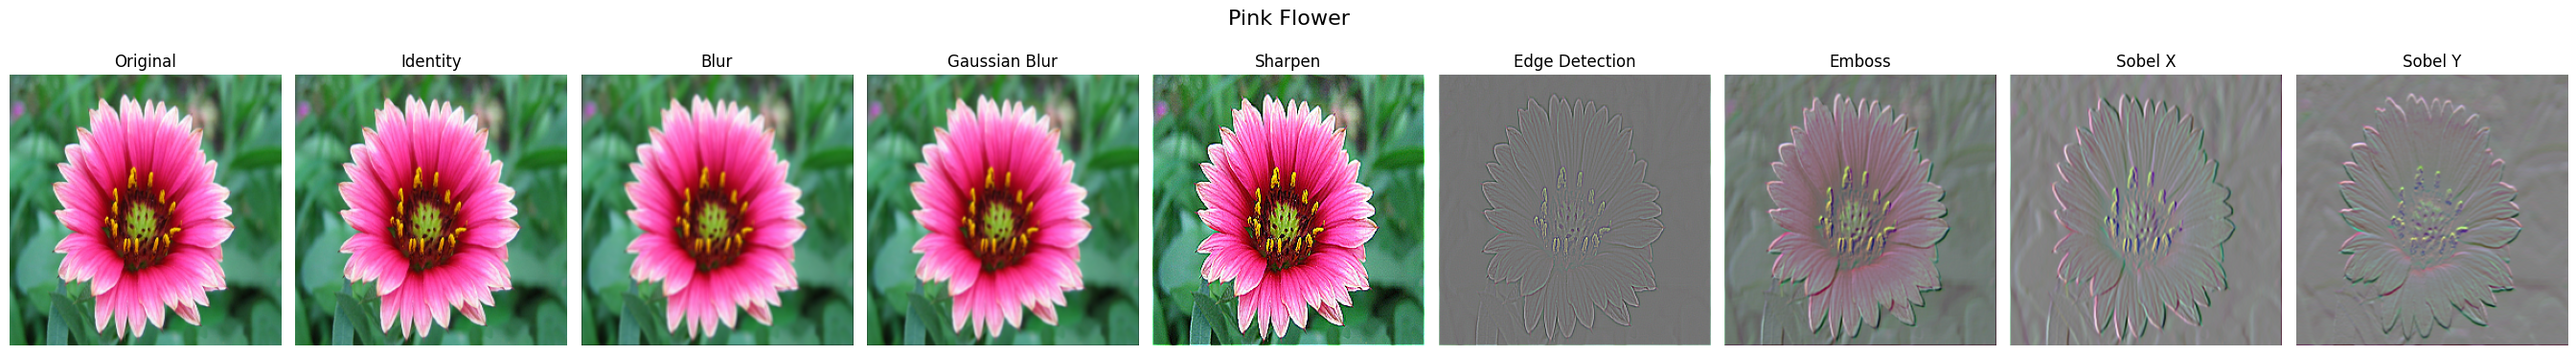

In [42]:
for image_name, image in images.items():

    n = len(filters) + 1
    fig, axes = plt.subplots(1, n, figsize=(3*n, 4))

    axes[0].imshow(image.numpy())
    axes[0].set_title("Original")
    axes[0].axis("off")

    for i, (filter_name, kernel) in enumerate(filters.items(), 1):

        filtered = apply_filter(image, kernel)

        # Normalize signed responses for visualization
        if filter_name in ["Edge Detection", "Sobel X", "Sobel Y", "Emboss"]:
            filtered = filtered.numpy()
            filtered = (filtered - filtered.min()) / (
                filtered.max() - filtered.min() + 1e-8
            )
        else:
            filtered = tf.clip_by_value(filtered, 0, 1).numpy()

        axes[i].imshow(filtered)
        axes[i].set_title(filter_name)
        axes[i].axis("off")

    plt.suptitle(image_name, fontsize=16)
    plt.tight_layout()
    plt.show()

In [ ]:
X --> conv(w1) --> conv(w2) --> conv(w3) --> neural(w4) -> yp <> [0, 1, 0, 0, 0] or [0, 1, 0, 0, 0] -> cross entropy
